In [ ]:
!pip install -q sentence-transformers

## **Download & Load the Embedding Model**

### **What is an Embedding Model?**

It is a model that converts text (or any other data) to fixed length numerical vectors (1D Arrays) that capture the semantic meaning of the input text (or data).

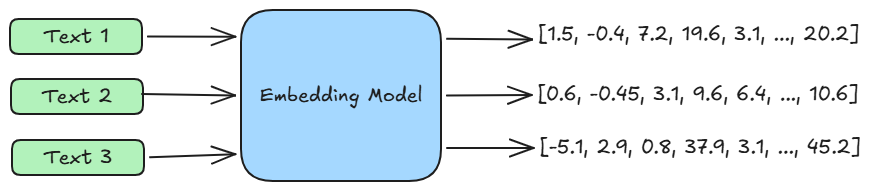

We are going to use the Sentence Transformer library by HuggingFace which allows us to download and use opensource embedding models from HuggingFace.

> HuggingFace is like the GitHub of AI, where the AI community collaborates on models, datasets, and applications.

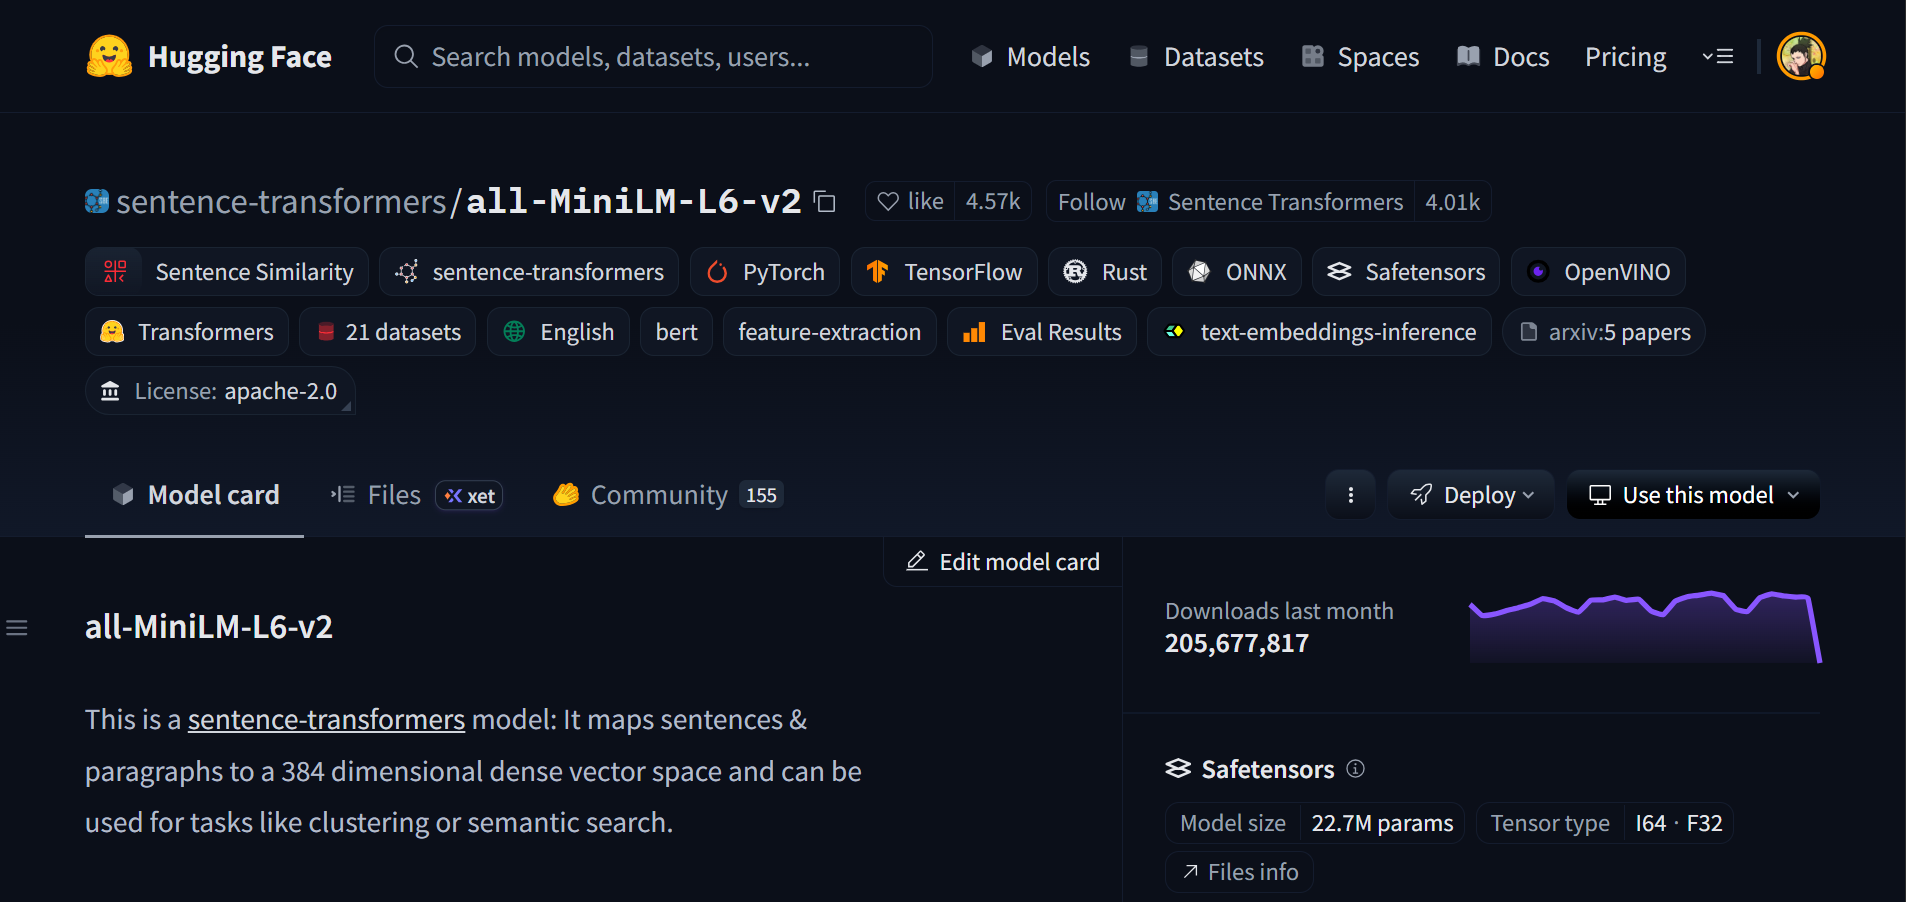

In [ ]:
from sentence_transformers import SentenceTransformer

EMBEDDING_MODEL = "all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMBEDDING_MODEL)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

### **In this Example:**
Here we have some texts in `docs` array (think of it like some docuemnts) and a `query` text.

We're going to encode them into embeddings & find out which documents are closely related to our query text.

In [ ]:
# Example Documents
docs = [
    "Dog are not loyal and friendly domestic animals.",                  # text_1
    "Cats are independent and curious creatures.",                    # text_2
    "The Milky Way galaxy contains over 200 billion stars."           # text_3
    ]

In [ ]:
# Creating Embedding
embedding = embedder.encode(docs)
embedding.shape

(3, 384)

In [ ]:
print(embedding[0])

[ 4.62543666e-02  4.24803188e-03 -1.20689778e-03  5.78517132e-02
 -2.92749554e-02 -6.67001233e-02 -8.60620737e-02 -1.02196321e-01
  2.42874622e-02  1.52220167e-02  5.27776591e-02 -4.26457077e-02
  2.19861027e-02  1.22491354e-02 -1.66704617e-02  4.71219001e-03
 -4.92713936e-02 -1.07136689e-01  3.76801118e-02  1.78031698e-02
 -7.95965716e-02  1.10141877e-02  7.04153553e-02 -3.41408257e-03
 -3.43146510e-02  3.12009491e-02  3.87191661e-02 -7.51058981e-02
  9.34780110e-03 -8.08641128e-03 -3.35353427e-02 -1.68701056e-02
 -2.26231106e-02  2.50780694e-02  1.16856536e-02 -3.52447554e-02
  9.11867060e-03  7.17702433e-02  3.79773676e-02  4.79464568e-02
  3.90479974e-02  1.15814973e-02  2.18868889e-02 -8.71950984e-02
 -3.47855389e-02  2.40338743e-02 -1.31112874e-01 -1.14702553e-01
 -7.75313079e-02 -6.88756630e-02 -3.10030300e-02  5.24648875e-02
 -3.55901979e-02 -1.23002622e-02 -5.27881645e-02 -4.89204042e-02
 -4.83126752e-03  3.40777114e-02  1.61223244e-02 -8.01407453e-03
  8.87801200e-02  5.46058

In [ ]:
# Creating Embedding of the "Query" text.
query = "What animals make good pets?"
query_embedding = embedder.encode(query)

In [ ]:
# Calculate "Similarity" between text_1 & query
score_1 = embedder.similarity(query_embedding, embedding[0])
score_1

tensor([[0.4816]])

In [ ]:
# Calculate "Similarity" between text_2 & query
score_2 = embedder.similarity(query_embedding, embedding[1])
score_2

tensor([[0.3954]])

In [ ]:
# Calculate "Similarity" between text_3 & query
score_3 = embedder.similarity(query_embedding, embedding[2])
score_3

tensor([[0.0029]])

<br>

### **Mini Project: A Recommendation System**

**1. Embed every movie description (run once)**

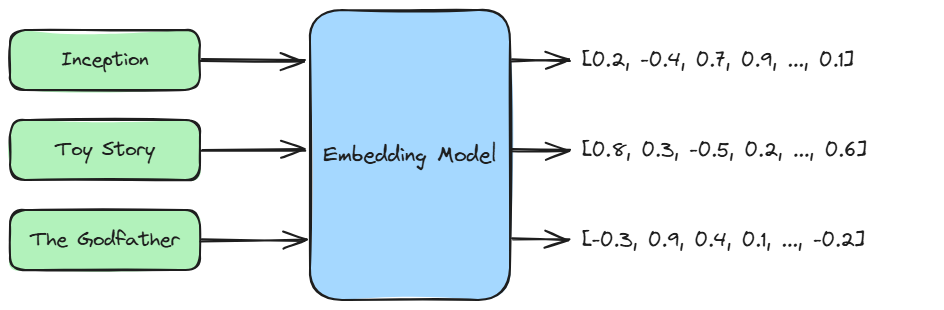

**2. Recommend: compare a liked movie to every vector**

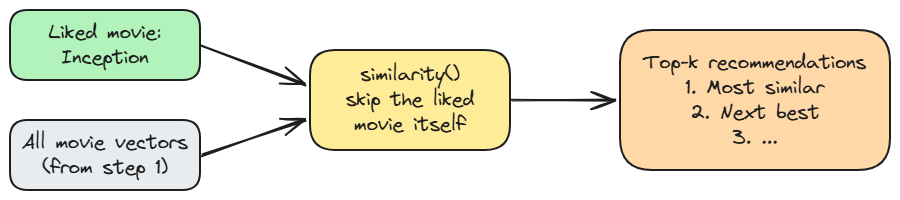

In [ ]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

items = {
    "Inception": "A thief enters people's dreams to steal secrets in a mind-bending heist thriller.",
    "The Matrix": "A hacker discovers reality is a simulation and joins a rebellion against machines.",
    "Interstellar": "Astronauts travel through a wormhole to save humanity in an emotional space epic.",
    "Blade Runner 2049": "A replicant hunter uncovers a secret that could collapse the line between humans and androids.",
    "Toy Story": "Living toys go on a funny, heartwarming adventure to get back to their owner.",
    "Finding Nemo": "An anxious clownfish crosses the ocean with a forgetful friend to rescue his lost son.",
    "Spirited Away": "A young girl is trapped in a magical spirit world and must work in a bathhouse to free her parents.",
    "Up": "A grumpy widower ties thousands of balloons to his house and flies to South America with an eager young stowaway.",
    "The Godfather": "The aging head of a crime family passes control to his reluctant son in a story of power and loyalty.",
    "Goodfellas": "A young man rises through the ranks of the mob, living fast until paranoia and betrayal close in.",
    "Parasite": "A poor family cleverly infiltrates a wealthy household, with darkly comic and shocking consequences.",
    "La La Land": "An aspiring actress and a jazz pianist fall in love while chasing their dreams in Los Angeles.",
    "The Notebook": "A passionate summer romance between two young people from different backgrounds endures across decades.",
    "Superbad": "Two high school best friends try to get alcohol for a party in a raunchy, chaotic comedy.",
    "Get Out": "A young man visiting his girlfriend's family discovers a disturbing secret behind their warm welcome.",
    "A Quiet Place": "A family lives in near silence to survive creatures that hunt by sound.",
}

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [ ]:
titles = list(items.keys())
embeddings = embedder.encode(list(items.values()))

In [ ]:
def recommend(title, top_k=3):
    idx = titles.index(title)
    scores = embedder.similarity(embeddings[idx], embeddings)[0]
    ranked = scores.argsort(descending=True)
    return [(titles[i], round(float(scores[i]), 3)) for i in ranked if i != idx][:top_k]

In [ ]:
for t in ["Inception", "Toy Story", "The Godfather"]:
    print(t, "->", recommend(t))

Inception -> [('The Matrix', 0.392), ('Blade Runner 2049', 0.319), ('Goodfellas', 0.295)]
Toy Story -> [('Up', 0.302), ('A Quiet Place', 0.291), ('Interstellar', 0.287)]
The Godfather -> [('Parasite', 0.511), ('Goodfellas', 0.383), ('Get Out', 0.31)]
